# 27. Where the bytes go

[Course plan](../../README.md)

The sculpture from lesson 20 fits in a small file. Opening it creates an image. Training it keeps several more arrays alive at the same time. A system monitor will show a very different number. One splat is small enough to count by hand.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
course = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "compression_math.py").is_file())
if str(course) not in sys.path:
    sys.path.insert(0, str(course))
import json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
import compression_math as codec
import compression_demos as demos
from reconstruction import scores, benchmark
from splat_render import render_scene, orbit_camera
lang = "en"

## One splat first

Its center has three coordinates measured in meters. Its three widths are positive lengths in meters. Four quaternion components describe orientation. Color has three channels between 0 and 1. Opacity contributes one more number in that range. That makes $3+3+4+3+1=14$ numbers. Float32 assigns 32 bits to each number. A byte has 8 bits, so one number takes $32/8=4$ bytes. One splat takes $14\cdot4=56$ bytes.

The sculpture has 117 splats. The centers alone take $117\cdot3\cdot4=1404$ bytes. All the numeric values take $117\cdot56=6552$ bytes. A binary file adds a header. Text JSON also carries field names, brackets and the digits of decimal numbers. The next cell reads the file and builds the binary packet.

In [2]:
scene, frames = codec.photo_data()
packet = codec.pack_static(scene, 'f32')
print('JSON, bytes:', (codec.ASSETS / 'photo-reference.json').stat().st_size)
print('GSC1, bytes:', len(packet), '= 8 +', len(packet)-8)
print('float32 parameters:', np.empty((117, 14), dtype=np.float32).nbytes)

JSON, bytes: 39038
GSC1, bytes: 6560 = 8 + 6552
float32 parameters: 6552


## When red depends on the view

Constant RGB has one number per channel. In a spherical-harmonic expansion the degree $L$ is a nonnegative integer. Each additional degree adds two more functions than the preceding degree did. Degree zero has one function. Degree one adds three, degree two adds five. Through degree three there are $1+3+5+7=16$ functions. Each needs one coefficient per channel, giving $3\cdot16=48$ color coefficients. These take space before a single pixel is drawn.

The sum of these odd numbers is $(L+1)^2$. At $L=3$ this gives $(3+1)^2=4\cdot4=16$. Let $N$ count the splats. Each splat also has $3+3+4+1=11$ numbers outside color. The parameter total in **bytes** is

$$
B=4N\left(11+3(L+1)^2\right).
$$

For 117 splats at degree three, $4\cdot117\cdot(11+48)=27612$ bytes. The degree control changes the assumed layout. The actual sculpture still uses constant RGB.

In [3]:
display(demos.codec_lab(27, lang))

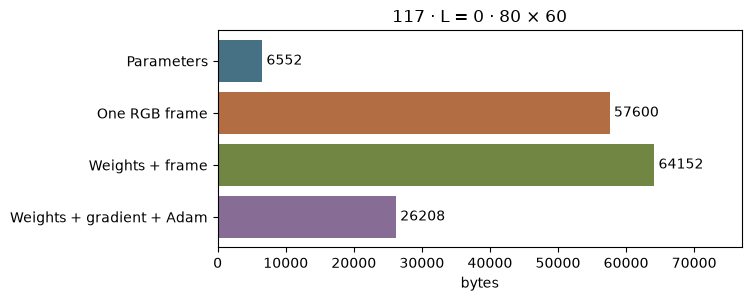

In [4]:
demos.storage_figure(lang, count=117, degree=0, width=80)
plt.show()

## The screen needs space too

An 80 by 60 frame contains $80\cdot60=4800$ pixels. Three float32 channels take $4800\cdot3\cdot4=57600$ bytes. Adding the sculpture parameters gives $57600+6552=64152$ bytes. In the experiment, height is three quarters of width rounded to the nearest pixel. Doubling both dimensions quadruples the number of pixels.

This count describes specific dense arrays. The course renderer actually returns float64 RGB, with 8 bytes per channel. The cell measures just the array elements with `nbytes`. Python objects, intermediate arrays, projections and libraries also occupy space. A GPU implementation has tile lists and device scratch space. The file length alone cannot tell us their size.

(60, 80, 3) float64 115200
float32 copy: 57600


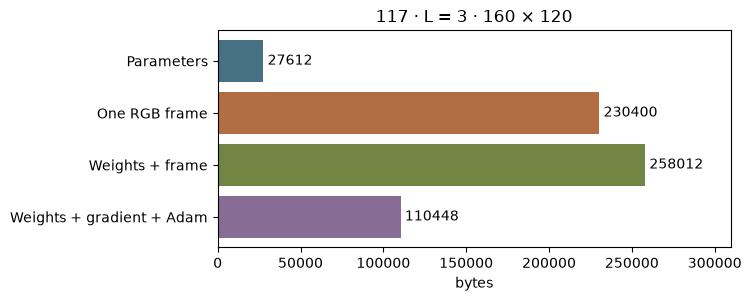

In [5]:
img = render_scene(scene, frames['view-04.jpg']['camera'], 80, 60)
print(img.shape, img.dtype, img.nbytes)
print('float32 copy:', img.astype(np.float32).nbytes)
demos.storage_figure(lang, count=117, degree=3, width=160)
plt.show()

## What training adds

For this count all 14 parameters train in float32. Their gradients take an array of the same shape. Adam keeps a running average of past gradients and a running average of their squares, two more arrays. That makes four equal sets. For the sculpture, $4\cdot6552=26208$ bytes cover **these four arrays**. Other costs depend on the implementation, the visible splats and the values retained for backpropagation. A viewer loading the final scene can discard the gradients and the two running averages.

**Experiment.** With 117 splats, which costs more: raising color degree from zero to three, or adding another 80 × 60 float32 RGB frame?

<details>
<summary>Worked answer</summary>

The extra coefficients cost $27612-6552=21060$ bytes. The frame takes 57600 bytes. The second buffer costs $57600-21060=36540$ bytes more. At a million splats the balance changes because the frame size stays fixed.

</details>